# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

# В sklearn 1.6 явный multi_class ещё поддерживается, как требует условие.
# Скрываем только предупреждение о его будущем удалении, но не о сходимости.
warnings.filterwarnings('ignore', message="'multi_class' was deprecated", category=FutureWarning)
warnings.filterwarnings('error', category=ConvergenceWarning)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True})
SEED = 42

frame = pd.read_csv('car_data.csv', header=None, index_col=0)
# Первый столбец CSV — сохранённый индекс строки, не признак автомобиля.
assert np.array_equal(frame.index, np.arange(len(frame)))
with open('column_names.json') as file:
    feature_names = json.load(file)
frame.columns = feature_names
assert frame.shape[1] == 19
assert frame.notna().all().all()
data = frame.iloc[:, :-1].to_numpy(dtype=float)
target = frame.iloc[:, -1].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.35, stratify=target, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
classes = np.unique(y_train)
print('All:', data.shape, 'train:', X_train.shape, 'test:', X_test.shape)
print('Train classes:', pd.Series(y_train).value_counts().sort_index().to_dict())
print('Missing values:', frame.isna().sum().sum())
print('Identical full rows:', frame.duplicated().sum())


All: (846, 18) train: (549, 18) test: (297, 18)
Train classes: {'bus': 141, 'opel': 138, 'saab': 141, 'van': 129}
Missing values: 0
Identical full rows: 0


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train, columns=feature_names[:-1])
X_train_pd.head(15)


,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PRAXIS ASPECT RATIO,MAXLENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PRAXIS RECTANGULARITY,MAXLENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
0,92.0,35.0,58.0,136.0,58.0,6.0,122.0,55.0,17.0,132.0,142.0,222.0,116.0,64.0,6.0,17.0,197.0,203.0
1,85.0,42.0,59.0,132.0,58.0,7.0,149.0,46.0,19.0,144.0,166.0,320.0,172.0,83.0,8.0,4.0,179.0,182.0
2,90.0,50.0,90.0,188.0,61.0,10.0,181.0,36.0,21.0,158.0,211.0,492.0,220.0,69.0,6.0,19.0,191.0,199.0
3,93.0,42.0,88.0,188.0,62.0,10.0,183.0,36.0,21.0,141.0,208.0,504.0,168.0,70.0,3.0,12.0,189.0,197.0
4,89.0,38.0,78.0,153.0,61.0,7.0,146.0,46.0,19.0,127.0,166.0,314.0,142.0,69.0,0.0,9.0,187.0,194.0
5,105.0,54.0,96.0,185.0,57.0,10.0,219.0,30.0,25.0,170.0,231.0,706.0,217.0,75.0,5.0,12.0,187.0,195.0
6,91.0,42.0,81.0,193.0,69.0,5.0,169.0,38.0,20.0,137.0,184.0,434.0,156.0,68.0,3.0,23.0,198.0,204.0
7,82.0,44.0,72.0,118.0,52.0,7.0,152.0,44.0,19.0,147.0,174.0,340.0,177.0,82.0,2.0,2.0,180.0,185.0
8,95.0,46.0,104.0,208.0,66.0,9.0,191.0,35.0,22.0,148.0,210.0,543.0,169.0,68.0,0.0,28.0,190.0,200.0
9,87.0,43.0,65.0,127.0,56.0,8.0,149.0,46.0,19.0,143.0,169.0,322.0,171.0,85.0,6.0,3.0,180.0,182.0


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PRAXIS ASPECT RATIO,MAXLENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PRAXIS RECTANGULARITY,MAXLENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,93.438980,44.790528,81.950820,168.859745,61.790528,8.664845,168.520947,41.032787,20.557377,147.846995,188.349727,438.347905,174.222222,72.473588,6.247723,12.468124,188.903461,195.584699
std,8.108886,6.179923,15.567587,33.484668,8.232802,5.161326,33.247222,7.847940,2.603844,14.575073,31.119292,176.757239,32.940415,7.492194,4.763438,9.041338,6.170906,7.396156
min,73.000000,33.000000,40.000000,104.000000,47.000000,3.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,112.000000,60.000000,0.000000,0.000000,176.000000,181.000000
25%,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,33.000000,19.000000,137.000000,167.000000,316.000000,149.000000,67.000000,2.000000,5.000000,184.000000,191.000000
50%,93.000000,44.000000,79.000000,167.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,178.000000,362.000000,173.000000,72.000000,6.000000,11.000000,189.000000,197.000000
75%,99.000000,49.000000,98.000000,195.000000,65.000000,10.000000,198.000000,46.000000,23.000000,159.000000,217.000000,587.000000,198.000000,76.000000,9.000000,18.000000,193.000000,201.000000
max,115.000000,59.000000,112.000000,322.000000,133.000000,55.000000,262.000000,61.000000,28.000000,186.000000,285.000000,998.000000,268.000000,127.000000,22.000000,41.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   COMPACTNESS                       549 non-null    float64
 1   CIRCULARITY                       549 non-null    float64
 2   DISTANCE CIRCULARITY              549 non-null    float64
 3   RADIUS RATIO                      549 non-null    float64
 4   PRAXIS ASPECT RATIO               549 non-null    float64
 5   MAXLENGTH ASPECT RATIO            549 non-null    float64
 6   SCATTER RATIO                     549 non-null    float64
 7   ELONGATEDNESS                     549 non-null    float64
 8   PRAXIS RECTANGULARITY             549 non-null    float64
 9   MAXLENGTH RECTANGULARITY          549 non-null    float64
 10  SCALED VARIANCE ALONG MAJOR AXIS  549 non-null    float64
 11  SCALED VARIANCE ALONG MINOR AXIS  549 non-null    float64
 12  SCALED R

### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
# Масштабирование внутри Pipeline заново обучается в каждом фолде CV.
# Для исследования PCA отдельно строим scaler только по train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Train feature ranges:')
display(X_train_pd.agg(['min', 'max', 'std']).round(2))
print('Number of constant train features:', np.sum(X_train.std(axis=0) == 0))

results = []

def evaluate(name, model):
    prediction = model.predict(X_test)
    row = {'model': name, 'accuracy': accuracy_score(y_test, prediction),
           'f1_macro': f1_score(y_test, prediction, average='macro')}
    results.append(row)
    display(pd.DataFrame([row]).round(4))


def plot_roc(model, title):
    probabilities = model.predict_proba(X_test)
    binary_target = label_binarize(y_test, classes=model.classes_)
    fig, ax = plt.subplots()
    for i, label in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(binary_target[:, i], probabilities[:, i])
        ax.plot(fpr, tpr, label=f'{label}: AUC={auc(fpr, tpr):.3f}')
    ax.plot([0, 1], [0, 1], 'k--', label='Random ranking')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=title)
    ax.legend()
    plt.show()


def predict_classes(probabilities, class_names):
    # В каждой строке ищем класс с наибольшей вероятностью.
    predictions = []
    for row in probabilities:
        class_index = np.argmax(row)
        predictions.append(class_names[class_index])
    return np.array(predictions)


Train feature ranges:


,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PRAXIS ASPECT RATIO,MAXLENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PRAXIS RECTANGULARITY,MAXLENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
min,73.00,33.00,40.00,104.00,47.00,3.00,112.00,26.00,17.0,118.00,130.00,184.00,112.00,60.00,0.00,0.00,176.00,181.0
max,115.00,59.00,112.00,322.00,133.00,55.00,262.00,61.00,28.0,186.00,285.00,998.00,268.00,127.00,22.00,41.00,206.00,211.0
std,8.11,6.18,15.57,33.48,8.23,5.16,33.25,7.85,2.6,14.58,31.12,176.76,32.94,7.49,4.76,9.04,6.17,7.4


Number of constant train features: 0


**Предобработка.** Первый столбец CSV — последовательный ID строки: удаляем его из признаков.
Оставшиеся 18 признаков числовые. Пропуски проверены явно, поэтому
импутация и кодирование категорий не требуются. Для LR и PCA нужен StandardScaler:
разные масштабы иначе меняют штраф LR и вклад признаков в дисперсию PCA.
Деревьям масштабирование не нужно. Разбиение фиксировано и стратифицировано,
35% объектов — test. Macro-F1 одинаково учитывает четыре класса; accuracy —
долю верных ответов. Ни scaler, ни PCA, ни поиск параметров не обучаются на test.


#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

Best parameters: {'lr__C': 10}
CV macro-F1: 0.7890579633885875
Iterations: [324]


,model,accuracy,f1_macro
0,Logistic regression,0.835,0.8344


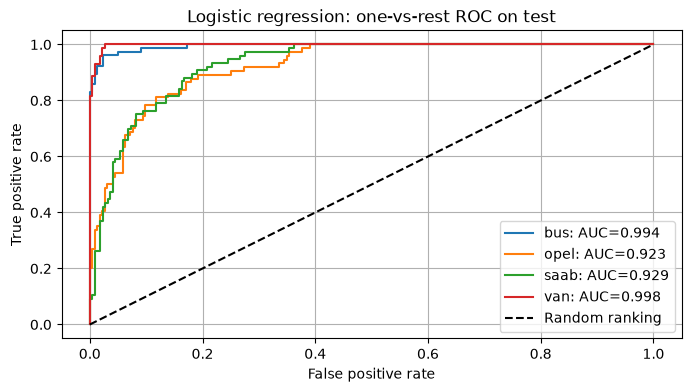

In [7]:
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('lr', LogisticRegression(multi_class='multinomial', solver='saga',
                              tol=1e-3, max_iter=500, random_state=SEED))
])
lr_search = GridSearchCV(
    lr_pipeline, {'lr__C': [0.01, 0.1, 1, 10]},
    scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise'
)
lr_search.fit(X_train, y_train)
best_lr = lr_search.best_estimator_
print('Best parameters:', lr_search.best_params_)
print('CV macro-F1:', lr_search.best_score_)
print('Iterations:', best_lr.named_steps['lr'].n_iter_)
evaluate('Logistic regression', best_lr)
plot_roc(best_lr, 'Logistic regression: one-vs-rest ROC on test')


**Логистическая регрессия.** Выбираем C по средней macro-F1 в пяти фолдах train;
после выбора GridSearchCV переобучает весь Pipeline на train. Меньшее C означает
более сильную регуляризацию. ROC построены one-vs-rest: для каждого класса его
вероятность сравнивается с индикатором «этот класс / остальные». Кривая использует
все пороги, тогда как accuracy и F1 относятся к выбору класса по максимальной
вероятности. AUC и F1 поэтому не взаимозаменяемы.

**Результат запуска.** C=10, CV macro-F1=0,7891; test accuracy=0,8350, macro-F1=0,8344. SAGA сошлась за 324 итерации из разрешённых 500. Классы bus и van отделяются лучше (AUC 0,994 и 0,998), чем opel и saab (0,923 и 0,929).


#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot. 

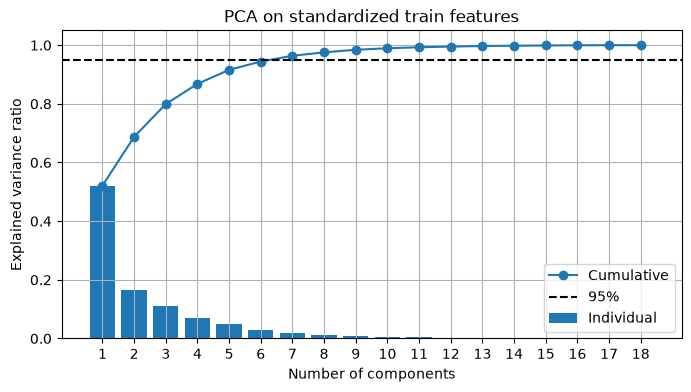

In [9]:
pca_full = PCA(svd_solver='full')
pca_full.fit(X_train_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
fig, ax = plt.subplots()
ax.bar(np.arange(1, len(explained) + 1), explained, label='Individual')
ax.plot(np.arange(1, len(explained) + 1), cumulative, 'o-', label='Cumulative')
ax.axhline(0.95, color='black', linestyle='--', label='95%')
ax.set(xlabel='Number of components', ylabel='Explained variance ratio',
       title='PCA on standardized train features', xticks=np.arange(1, 19))
ax.legend()
plt.show()


**Объяснённая дисперсия.** Столбцы показывают вклад отдельных компонент,
линия — накопленную долю. PCA использует только стандартизованный train,
без y. Коррелированные признаки дают возможность сжатия: первая компонента
не обязана быть одним из исходных признаков.

Первая компонента объясняет чуть больше половины дисперсии, а семь компонент вместе — 96,39%. Накопленная дисперсия быстро выходит на плато, что согласуется с сильной избыточностью признаков.


#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [10]:
# Порог 95% выбран заранее, без использования test и меток классов.
pca = PCA(n_components=0.95, svd_solver='full')
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print('Components:', pca.n_components_)
print('Retained variance:', pca.explained_variance_ratio_.sum())
print('Transformed shapes:', X_train_pca.shape, X_test_pca.shape)


Components: 7
Retained variance: 0.9639000750021123
Transformed shapes: (549, 7) (297, 7)


**Выбор компонент.** Берём минимальное число компонент, сохраняющее не менее
95% train-дисперсии. Масштабирование необходимо, поскольку признаки имеют разные
единицы и диапазоны. Только train используется для fit scaler и PCA; test проходит
лишь transform. Порог дисперсии не гарантирует сохранения информации о классах:
дискриминативное направление может иметь малую дисперсию.

В этом запуске выбрано 7 компонент из 18; формы после transform — (549, 7) и (297, 7).


**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

Best parameters: {'lr__C': 10}
CV macro-F1: 0.6289186336069178


,model,accuracy,f1_macro
0,PCA + logistic regression,0.6195,0.6153


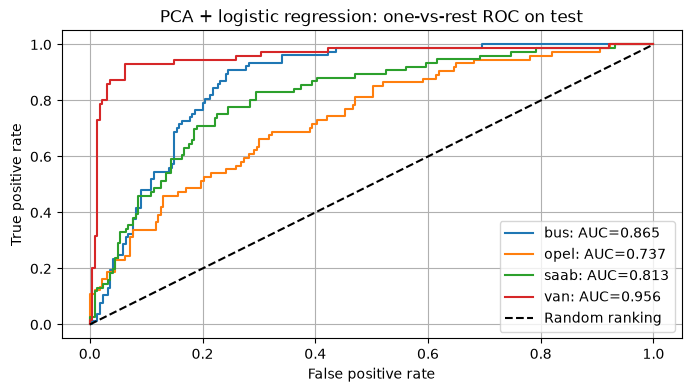

In [11]:
# В CV нельзя подать X_train_pca: тогда PCA уже видела validation-фолды.
# Весь preprocessing обучаем внутри каждого фолда.
pca_lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('lr', LogisticRegression(multi_class='multinomial', solver='saga',
                              tol=1e-3, max_iter=500, random_state=SEED))
])
pca_lr_search = GridSearchCV(
    pca_lr_pipeline, {'lr__C': [0.01, 0.1, 1, 10]},
    scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise'
)
pca_lr_search.fit(X_train, y_train)
best_pca_lr = pca_lr_search.best_estimator_
print('Best parameters:', pca_lr_search.best_params_)
print('CV macro-F1:', pca_lr_search.best_score_)
evaluate('PCA + logistic regression', best_pca_lr)
plot_roc(best_pca_lr, 'PCA + logistic regression: one-vs-rest ROC on test')


**LR после PCA.** В CV повторно обучаем scaler и PCA на каждом train-фолде,
иначе статистики validation попали бы в преобразование. Потеря части направлений
может ухудшить классификацию даже при сохранении 95% дисперсии; польза PCA здесь
проверяется метриками, а не предполагается по определению.

**Результат запуска.** При C=10 CV macro-F1=0,6289, test accuracy=0,6195, macro-F1=0,6153. По сравнению с LR на всех признаках падение заметное; ROC также ухудшились. Значит, сохранённая общая дисперсия не сохранила все полезные для различения классов направления. По этому эксперименту PCA с порогом 95% перед LR невыгодна.


#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [12]:
# Дерево использует исходные признаки: масштабирование не меняет порядок значений.
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    {'max_depth': [2, 3, 4, 5, 7, 10, None]},
    scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise'
)
tree_search.fit(X_train, y_train)
best_tree = tree_search.best_estimator_
print('Best parameters:', tree_search.best_params_)
print('CV macro-F1:', tree_search.best_score_)
evaluate('Decision tree', best_tree)


Best parameters: {'max_depth': 7}
CV macro-F1: 0.675373616803954


,model,accuracy,f1_macro
0,Decision tree,0.7205,0.7171


**Дерево.** Подбираем max_depth по macro-F1 на тех же фолдах train. Дерево
строит осевые разбиения и может моделировать нелинейности, но одно дерево
чувствительно к составу небольшой выборки. Для сопоставимости используем
исходные 18 признаков, как у базовой LR, без PCA.

**Результат запуска.** Выбрана глубина 7, CV macro-F1=0,6754; test accuracy=0,7205, macro-F1=0,7171. На данном разбиении одиночное дерево уступает LR; нелинейность модели сама по себе не гарантирует улучшения.


#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble? 

LR: selected N=17, OOB F1=0.7837
Tree: selected N=97, OOB F1=0.7365


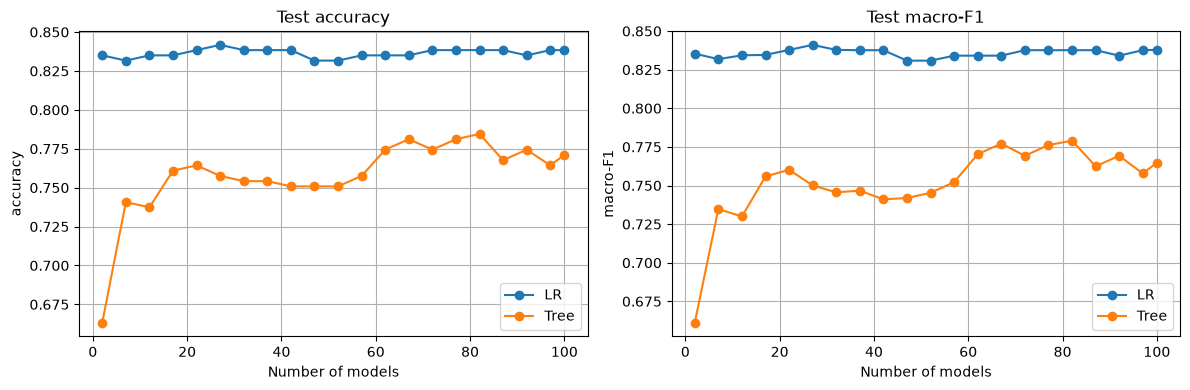

In [13]:
# 2, 7, ..., 97; отдельно включаем верхнюю границу 100.
ensemble_sizes = np.append(np.arange(2, 101, 5), 100)
rng = np.random.default_rng(SEED)
bootstrap_indices = []
for number in range(100):
    indices = rng.choice(len(X_train), len(X_train), replace=True)
    bootstrap_indices.append(indices)
# Одни и те же bootstrap-выборки для обеих семей моделей.
bagging_curves = {}
bagging_rows = {}
bagging_models = {}

for family, base_model in [('LR', best_lr), ('Tree', best_tree)]:
    models = []
    test_sum = np.zeros((len(X_test), len(classes)))
    oob_sum = np.zeros((len(X_train), len(classes)))
    oob_counts = np.zeros(len(X_train), dtype=int)
    rows = []
    for number, indices in enumerate(bootstrap_indices, start=1):
        # clone создаёт новую необученную модель с теми же параметрами.
        model = clone(base_model)
        model.fit(X_train[indices], y_train[indices])
        # На этом датасете все bootstrap-выборки содержат все четыре класса.
        assert np.array_equal(model.classes_, classes)
        models.append(model)
        test_sum += model.predict_proba(X_test)
        seen_indices = set(indices)
        oob_indices = []
        for i in range(len(X_train)):
            if i not in seen_indices:
                oob_indices.append(i)
        if oob_indices:
            oob_sum[oob_indices] += model.predict_proba(X_train[oob_indices])
            oob_counts[oob_indices] += 1
        if number in ensemble_sizes:
            average_probabilities = test_sum / number
            test_prediction = predict_classes(average_probabilities, classes)

            # Берём только объекты, у которых уже есть OOB-прогноз.
            oob_predictions = []
            oob_targets = []
            for i in range(len(X_train)):
                if oob_counts[i] > 0:
                    average = oob_sum[i] / oob_counts[i]
                    class_index = np.argmax(average)
                    oob_predictions.append(classes[class_index])
                    oob_targets.append(y_train[i])
            rows.append({
                'N': number,
                'test_accuracy': accuracy_score(y_test, test_prediction),
                'test_f1_macro': f1_score(y_test, test_prediction, average='macro'),
                'oob_f1_macro': f1_score(oob_targets, oob_predictions, average='macro'),
                'oob_coverage': len(oob_predictions) / len(X_train)
            })
    bagging_models[family] = models
    bagging_rows[family] = rows
    bagging_curves[family] = pd.DataFrame(rows)

# Выбор N только по train OOB; при равенстве выигрывает меньшее N.
# Не сравниваем оценки с низким покрытием: заранее требуем >=99% объектов.
best_bagging_sizes = {}
for family, rows in bagging_rows.items():
    best_row = None
    for row in rows:
        if row['oob_coverage'] < 0.99:
            continue
        if best_row is None:
            best_row = row
        elif row['oob_f1_macro'] > best_row['oob_f1_macro']:
            best_row = row

    best_size = best_row['N']
    best_bagging_sizes[family] = best_size
    print(f"{family}: selected N={best_size}, OOB F1={best_row['oob_f1_macro']:.4f}")
    results.append({
        'model': f'Bagging {family} (N={best_size})',
        'accuracy': best_row['test_accuracy'],
        'f1_macro': best_row['test_f1_macro']
    })

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for family, curve in bagging_curves.items():
    axes[0].plot(curve.N, curve.test_accuracy, 'o-', label=family)
    axes[1].plot(curve.N, curve.test_f1_macro, 'o-', label=family)
for ax, metric in zip(axes, ['accuracy', 'macro-F1']):
    ax.set(xlabel='Number of models', ylabel=metric, title=f'Test {metric}')
    ax.legend()
plt.tight_layout()
plt.show()


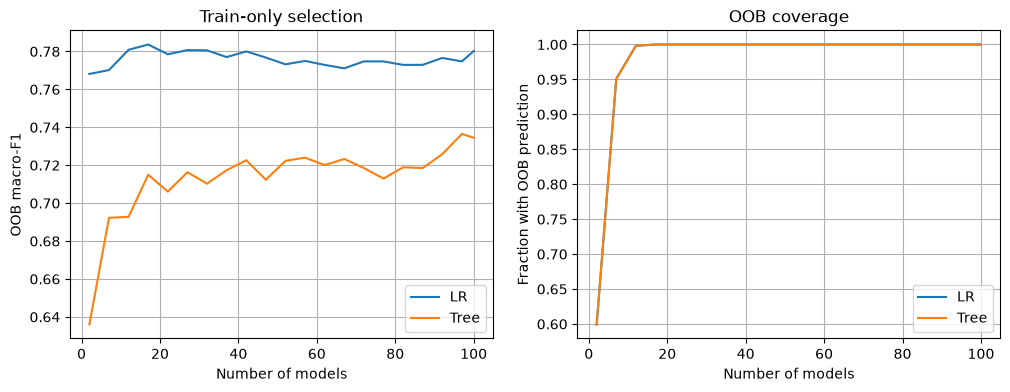

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for family, curve in bagging_curves.items():
    axes[0].plot(curve.N, curve.oob_f1_macro, label=family)
    axes[1].plot(curve.N, curve.oob_coverage, label=family)
axes[0].set(xlabel='Number of models', ylabel='OOB macro-F1', title='Train-only selection')
axes[1].set(xlabel='Number of models', ylabel='Fraction with OOB prediction', title='OOB coverage')
for ax in axes:
    ax.legend()
plt.show()


**Бэггинг.** Усредняем вероятности 100 независимо обученных моделей, а не
номера классов. Кривые построены для 2, 7, …, 97 и дополнительно 100 моделей.
Число моделей выбираем по OOB macro-F1 только среди точек с покрытием не менее
99% train; test-кривые служат описанием, не критерием выбора.
«Оптимальное N» здесь — максимум на конечной сетке для данного seed, а не
теоретически единственное число. OOB-оценка после подбора глубины/C на всём train
может быть оптимистичной: это критерий выбора N, а не независимая оценка качества.
Независимую оценку даёт отложенный test. Плато означает, что новые модели дают мало пользы.

Глубина, лучшая для одиночного дерева, не обязана быть лучшей для бэггинга.
Усреднение уменьшает дисперсию, поэтому более глубокие деревья могут оказаться
выгоднее. В этом пункте следуем условию и используем ранее найденную глубину;
для оптимизации всего ансамбля следовало бы отдельно подбирать её по train CV/OOB.
Бэггинг LR обычно даёт меньший выигрыш: регуляризованная LR стабильнее дерева.

**Результат запуска.** OOB-критерий выбрал 17 LR и 97 деревьев. У LR test accuracy=0,8350, macro-F1=0,8346 — практически как у одной LR; кривая почти плоская. У деревьев accuracy=0,7643 и macro-F1=0,7578, что выше одиночного дерева. Основной рост идёт в начале, затем видны колебания; точный максимум по OOB не совпадает обязательно с максимумом test-кривой. Выбор N после просмотра test не менялся.


#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

Selected trees by OOB macro-F1: 57


,model,accuracy,f1_macro
0,Random forest,0.7643,0.7596


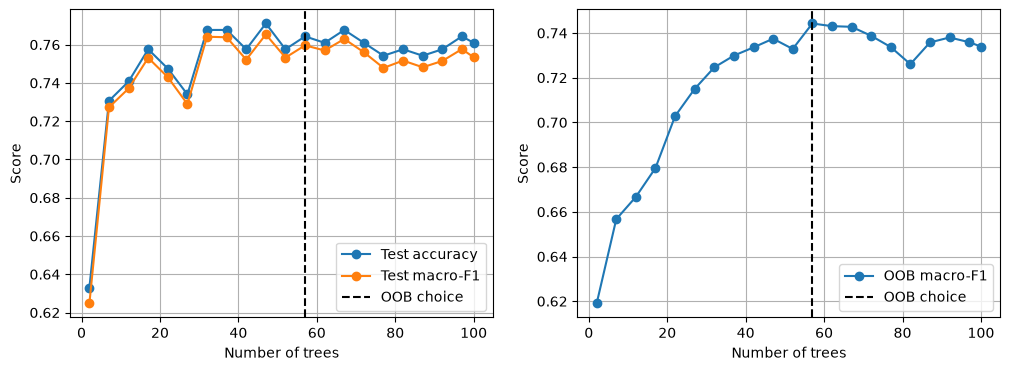

In [15]:
rf_rows = []
for number in ensemble_sizes:
    # Для каждого размера создаём новый лес с тем же random_state.
    rf = RandomForestClassifier(
        n_estimators=int(number), max_features='sqrt', max_depth=None,
        bootstrap=True, oob_score=True, random_state=SEED, n_jobs=1
    )
    # При малом N sklearn предупреждает, что часть объектов ещё не имеет OOB-прогноза.
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Some inputs do not have OOB scores')
        rf.fit(X_train, y_train)
    prediction = rf.predict(X_test)
    oob_probabilities = rf.oob_decision_function_
    oob_predictions = []
    oob_targets = []
    for i in range(len(X_train)):
        # Нулевая строка означает, что OOB-прогноза пока нет.
        if oob_probabilities[i].sum() > 0:
            class_index = np.argmax(oob_probabilities[i])
            oob_predictions.append(rf.classes_[class_index])
            oob_targets.append(y_train[i])
    rf_rows.append({
        'N': int(number), 'test_accuracy': accuracy_score(y_test, prediction),
        'test_f1_macro': f1_score(y_test, prediction, average='macro'),
        'oob_f1_macro': f1_score(oob_targets, oob_predictions, average='macro'),
        'oob_coverage': len(oob_predictions) / len(X_train)
    })
rf_curve = pd.DataFrame(rf_rows)
best_row = None
for row in rf_rows:
    if row['oob_coverage'] < 0.99:
        continue
    if best_row is None:
        best_row = row
    elif row['oob_f1_macro'] > best_row['oob_f1_macro']:
        best_row = row

best_rf_size = best_row['N']
best_rf = RandomForestClassifier(
    n_estimators=best_rf_size, max_features='sqrt', max_depth=None,
    bootstrap=True, oob_score=True, random_state=SEED, n_jobs=1
)
best_rf.fit(X_train, y_train)
print('Selected trees by OOB macro-F1:', best_rf_size)
evaluate('Random forest', best_rf)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rf_curve.N, rf_curve.test_accuracy, 'o-', label='Test accuracy')
axes[0].plot(rf_curve.N, rf_curve.test_f1_macro, 'o-', label='Test macro-F1')
axes[1].plot(rf_curve.N, rf_curve.oob_f1_macro, 'o-', label='OOB macro-F1')
for ax in axes:
    ax.axvline(best_rf_size, linestyle='--', color='black', label='OOB choice')
    ax.set(xlabel='Number of trees', ylabel='Score')
    ax.legend()
plt.show()


**Случайный лес.** Кроме bootstrap, лес случайно ограничивает признаки
в каждом узле (sqrt), что уменьшает корреляцию деревьев. Здесь деревья полные:
их глубина не переносится автоматически из оптимума одиночного дерева.
N выбирается по OOB macro-F1 с тем же порогом покрытия. Отличие от бэггинга
может быть следствием и случайного выбора признаков, и иной глубины.
Сравнение не изолирует эффект только одного из этих факторов.

**Результат запуска.** Выбрано 57 деревьев, test accuracy=0,7643, macro-F1=0,7596. Это меньше OOB-оптимума бэггинга деревьев (97), но больше оптимума LR (17). После нескольких десятков деревьев test-кривая выходит примерно на плато. В данном опыте лес и бэггинг деревьев близки по качеству; LR остаётся лучше.


#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it? 

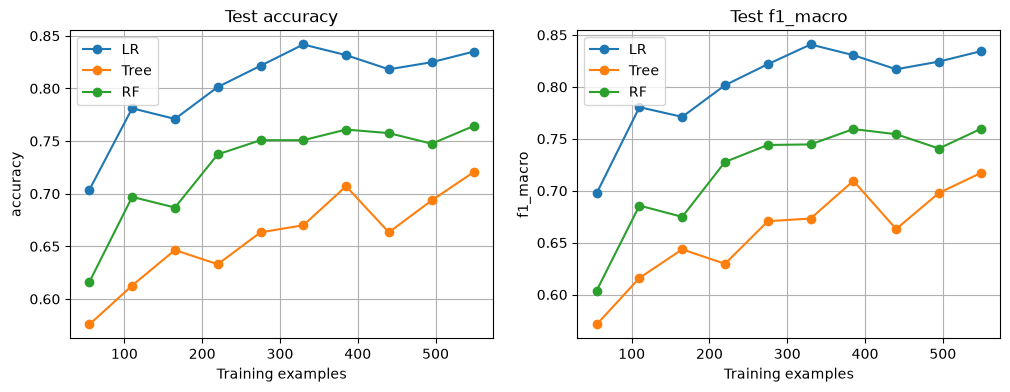

,model,train_size,accuracy,f1_macro
0,LR,55,0.7037,0.6976
1,Tree,55,0.5758,0.5712
2,RF,55,0.6162,0.6039
3,LR,110,0.7811,0.7805
4,Tree,110,0.6128,0.6160
5,RF,110,0.6970,0.6857
6,LR,165,0.7710,0.7711
7,Tree,165,0.6465,0.6436
8,RF,165,0.6869,0.6748
9,LR,220,0.8013,0.8016


In [16]:
# Десять почти равных частей с сохранением пропорций классов.
parts_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
parts = []
for train_indices, part_indices in parts_cv.split(X_train, y_train):
    parts.append(part_indices)
assert len(np.unique(np.concatenate(parts))) == len(X_train)
part_sizes = []
for part in parts:
    part_sizes.append(len(part))
assert max(part_sizes) - min(part_sizes) <= 1
learning_rows = []
for part_count in range(1, 11):
    indices = np.sort(np.concatenate(parts[:part_count]))
    for name, template in [('LR', best_lr), ('Tree', best_tree), ('RF', best_rf)]:
        model = clone(template)
        if name == 'RF':
            model.set_params(oob_score=False)
        model.fit(X_train[indices], y_train[indices])
        prediction = model.predict(X_test)
        learning_rows.append({
            'model': name, 'train_size': len(indices),
            'accuracy': accuracy_score(y_test, prediction),
            'f1_macro': f1_score(y_test, prediction, average='macro')
        })
learning_curve = pd.DataFrame(learning_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['LR', 'Tree', 'RF']:
    rows = learning_curve[learning_curve.model == name]
    for ax, metric in zip(axes, ['accuracy', 'f1_macro']):
        ax.plot(rows.train_size, rows[metric], 'o-', label=name)
        ax.set(xlabel='Training examples', ylabel=metric, title=f'Test {metric}')
for ax in axes:
    ax.legend()
plt.show()
display(learning_curve.round(4))


**Learning curve.** Части вложены друг в друга; гиперпараметры фиксированы
по предыдущим этапам. Масштабирование LR каждый раз обучается только на выбранной
части. Это один эксперимент с одним фиксированным test, поэтому небольшие колебания
кривых не следует считать устойчивыми закономерностями. Это не независимая оценка
полной процедуры подбора параметров: параметры ранее выбирались на всём train.
Для оценки разброса нужны повторные разбиения; по этим кривым нельзя гарантировать
монотонное улучшение при добавлении данных.

**Наблюдение.** При росте train от 55 до 549 примеров все три модели в целом улучшаются: LR примерно от 0,704 до 0,835 accuracy, дерево от 0,576 до 0,721, лес от 0,616 до 0,764. Рост не монотонный; у LR после нескольких сотен объектов выигрыш мал. Дерево остаётся слабее ансамбля и LR. Дополнительные данные могут помочь, но величину выигрыша за пределами выборки этот график не определяет.


#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

Selected boosting rounds: 285
Actual trees for multiclass boosting: 1140
Minimum CV log-loss: 0.5185033239117374


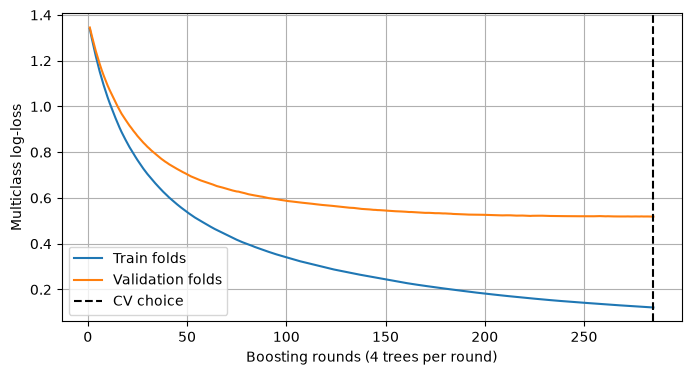

,accuracy,f1_macro
model,,
Logistic regression,0.8350,0.8344
PCA + logistic regression,0.6195,0.6153
Decision tree,0.7205,0.7171
Bagging LR (N=17),0.8350,0.8346
Bagging Tree (N=97),0.7643,0.7578
Random forest,0.7643,0.7596
XGBoost (285 rounds),0.8047,0.8034


In [17]:
import xgboost as xgb

# Нативный API, без XGBClassifier и без evals с тестовой выборкой.
encoder = LabelEncoder()
encoder.fit(y_train)
dtrain = xgb.DMatrix(X_train, label=encoder.transform(y_train))
dtest = xgb.DMatrix(X_test)
xgb_params = {
    'objective': 'multi:softprob', 'num_class': len(classes),
    'eval_metric': 'mlogloss', 'max_depth': 3, 'eta': 0.05,
    'subsample': 0.9, 'colsample_bytree': 0.9,
    'seed': SEED, 'nthread': 1, 'tree_method': 'hist'
}
boost_cv = xgb.cv(
    xgb_params, dtrain, num_boost_round=500,
    folds=list(cv.split(X_train, y_train)),
    early_stopping_rounds=30, verbose_eval=False, seed=SEED
)
best_rounds = int(boost_cv['test-mlogloss-mean'].argmin()) + 1
booster = xgb.train(xgb_params, dtrain, num_boost_round=best_rounds)
boost_probabilities = booster.predict(dtest)
encoded_classes = np.arange(len(classes))
encoded_predictions = predict_classes(boost_probabilities, encoded_classes)
boost_prediction = encoder.inverse_transform(encoded_predictions)
results.append({'model': f'XGBoost ({best_rounds} rounds)',
                'accuracy': accuracy_score(y_test, boost_prediction),
                'f1_macro': f1_score(y_test, boost_prediction, average='macro')})
print('Selected boosting rounds:', best_rounds)
print('Actual trees for multiclass boosting:', len(booster.get_dump()))
print('Minimum CV log-loss:', boost_cv['test-mlogloss-mean'].min())
fig, ax = plt.subplots()
ax.plot(boost_cv.index + 1, boost_cv['train-mlogloss-mean'], label='Train folds')
ax.plot(boost_cv.index + 1, boost_cv['test-mlogloss-mean'], label='Validation folds')
ax.axvline(best_rounds, color='black', linestyle='--', label='CV choice')
ax.set(xlabel='Boosting rounds (4 trees per round)', ylabel='Multiclass log-loss')
ax.legend()
plt.show()
results_table = pd.DataFrame(results).set_index('model')
display(results_table.round(4))


**Бустинг.** Число итераций выбирает пятифолдовая CV на train по log-loss
с ранней остановкой после 30 итераций без улучшения. Предел поиска — 500 итераций;
если минимум у границы, это ограничение поиска, а не доказанный оптимум.
В многоклассовом XGBoost на каждой итерации строятся четыре дерева, поэтому
число деревьев равно четырём числам итераций. Финальный booster переобучен на всём
train; test не используется для ранней остановки. Это нативные DMatrix, cv и train,
как требует условие.

**Результат запуска.** Выбрано 285 итераций (1140 деревьев), CV log-loss=0,5185; test accuracy=0,8047, macro-F1=0,8034. Предел 500 итераций не достигнут: ранняя остановка определила лучший префикс ансамбля. Бустинг улучшил одиночное дерево и лес на этом test, но не обошёл LR. Отставание не означает слабость бустинга вообще: остальные параметры здесь фиксированы, а сетка LR и размер данных ограничены.
